# Titanic - Limpeza e engenharia de features

O modelo só entende números e não aceita valores faltando. Aqui decidimos como preencher o que falta e criamos colunas novas (*features*) a partir das que já existem. As funções finais ficam em `src/features.py`, para o notebook de modelagem usar exatamente a mesma transformação.

In [1]:
import sys
sys.path.append('..')  # permite importar a pasta src/

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.features import extrair_titulo, criar_features

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

## 1. Valores faltantes no treino e no teste

In [2]:
pd.DataFrame({
    'treino': train.isnull().sum(),
    'teste': test.isnull().sum(),
})

,treino,teste
Age,177,86.0
Cabin,687,327.0
Embarked,2,0.0
Fare,0,1.0
Name,0,0.0
Parch,0,0.0
PassengerId,0,0.0
Pclass,0,0.0
Sex,0,0.0
SibSp,0,0.0


- **Age** falta nos dois (177 e 86). Vamos preencher com a mediana do treino.
- **Embarked** falta em 2 do treino: preenchemos com o porto mais comum.
- **Fare** falta em 1 do teste: mediana do treino.
- **Cabin** falta em 77% dos casos. Não dá para preencher, mas *ter ou não ter cabine registrada* pode ser informação (`HasCabin`).

**Regra de ouro:** medianas e valores mais comuns são calculados **só com o treino** e depois aplicados ao teste. Calcular com o teste seria usar informação que o modelo não deveria ver (*vazamento de dados*). Quem faz isso por nós é o `Pipeline` do scikit-learn, no próximo notebook.

## 2. Título extraído do nome

Todo nome tem um título entre a vírgula e o ponto: `Braund, Mr. Owen Harris`. Ele resume sexo, idade e status social.

In [3]:
train['Title'] = extrair_titulo(train['Name'])
train['Title'].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Raro       23
Name: count, dtype: int64

In [4]:
train.groupby('Title')['Survived'].mean().sort_values()

Title
Mr        0.156673
Raro      0.347826
Master    0.575000
Miss      0.702703
Mrs       0.793651
Name: Survived, dtype: float64

`Master` era o título de **meninos**: eles sobreviveram muito mais que os `Mr` (homens adultos). O título separa crianças de adultos mesmo quando a idade está faltando. Títulos raros (Dr, Rev, Col…) foram agrupados em `Raro`.

## 3. Tamanho da família

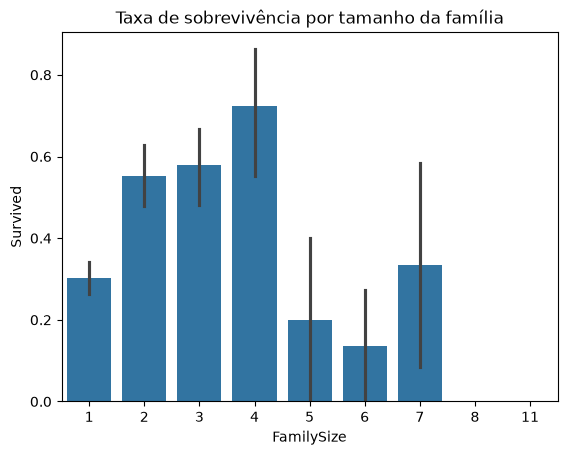

In [5]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

sns.barplot(data=train, x='FamilySize', y='Survived')
plt.title('Taxa de sobrevivência por tamanho da família')
plt.savefig('../reports/figures/sobrevivencia_familia.png', dpi=150, bbox_inches='tight')
plt.show()

Quem viajava **sozinho** (1) sobreviveu menos que famílias de 2 a 4 pessoas. Famílias grandes (5 ou mais) voltaram a sobreviver pouco, talvez pela dificuldade de reunir todos. Criamos também `IsAlone` (1 se viajava sozinho).

## 4. Ter cabine registrada

In [6]:
train['HasCabin'] = train['Cabin'].notna().astype(int)
train.groupby('HasCabin')['Survived'].mean()

HasCabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64

Quem tinha cabine registrada sobreviveu bem mais. Isso está muito ligado à 1ª classe, mas pode ajudar o modelo.

## 5. Resultado final

A função `criar_features` junta tudo e devolve só as colunas que o modelo vai usar.

In [7]:
X_treino = criar_features(train)
X_teste = criar_features(test)

X_treino.head()

,Age,Fare,SibSp,Parch,FamilySize,Pclass,Sex,Embarked,Title,IsAlone,HasCabin
0,22.0,7.2500,1,0,2,3,male,S,Mr,0,0
1,38.0,71.2833,1,0,2,1,female,C,Mrs,0,1
2,26.0,7.9250,0,0,1,3,female,S,Miss,1,0
3,35.0,53.1000,1,0,2,1,female,S,Mrs,0,1
4,35.0,8.0500,0,0,1,3,male,S,Mr,1,0


In [8]:
X_treino.shape, X_teste.shape

((891, 11), (418, 11))

Mesmas 11 colunas no treino e no teste. Os valores faltantes de `Age`, `Fare` e `Embarked` continuam lá de propósito: serão preenchidos dentro do Pipeline, junto com a conversão de `Sex`, `Embarked`, `Title` e `Pclass` em números (*one-hot encoding*).